# Figure S3

In [1]:
from riskhistory.format import rcParams
from riskhistory.config import results_pth
from riskhistory.data import load_ddm_posterior
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
DATASET_LABELS2 = {"equalIndifference" : "\nEqualIndifference",
                    "equalRange" : "EqualRange",
                    "sheng2020" : "\nSheng2020"}

### Helper functions

In [ ]:
def summarize_posterior(model_id, dataset, param):
    """Flatten the 4 chains into one pooled sample, then the 95% CI as the
    2.5th/97.5th percentiles."""
    posterior = load_ddm_posterior(model_id, dataset)
    samples = posterior[param].flatten()
    lo, hi = np.percentile(samples, [2.5, 97.5])
    return samples, np.mean(samples), lo, hi



def ln_bf_sign(samples):
    """ln Bayes Factor for the parameter being >0 vs. <0, from the
    (continuity-corrected) proportion of posterior mass on each side --
    equal to the posterior odds under a prior symmetric about zero."""
    n = len(samples)
    eps = 1 / (2 * n)
    p_pos = np.clip(np.mean(samples > 0), eps, 1 - eps)
    return np.log(p_pos / (1 - p_pos))


def plot_posterior_hists(ax, model_id, param, color, ylabel, ylim, bins=40, max_width=0.7):
    """Sideways histogram of the pooled posterior per dataset (bins on the
    y-axis), with the mean (horizontal line) and 95% interval (vertical
    line to the left of each histogram)."""
    for x, ds in enumerate(DATASETS):
        samples, mean, lo, hi = summarize_posterior(model_id, ds, param)
        counts, edges = np.histogram(samples, bins=bins)
        left = x - max_width / 2
        right_edges = left + max_width * counts / counts.max()
        ax.stairs(right_edges, edges, baseline=left, orientation="horizontal",
                  fill=True, color=color, zorder=3)
        ax.stairs(right_edges, edges, baseline=left, orientation="horizontal",
                  color="black", linewidth=1.5, zorder=3)
        ax.plot([left, left + max_width], [mean, mean], color="black",
                linewidth=2.5, zorder=4)
        ax.plot([left - 0.06, left - 0.06], [lo, hi], color="black",
                linewidth=2.5, solid_capstyle="butt", zorder=4)

    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)
    ax.set_xticks(range(len(DATASETS)))
    ax.set_xticklabels([DATASET_LABELS2[ds] for ds in DATASETS], ha="center", fontsize = plt.rcParams["axes.labelsize"]*1.1)
    ax.set_xlim(-0.6, len(DATASETS) - 0.4)
    ax.set_ylabel(ylabel, fontsize = plt.rcParams["axes.labelsize"]*1.1)
    ax.set_ylim(*ylim)
    ax.spines[["top", "right"]].set_visible(False)

### Pupil x Gain and Pupil x Loss drift parameters
Pooled group-level posterior per dataset from `HDDM_Base_Pupil_valuation`, as a sideways histogram (black line = mean, vertical line = 95% posterior interval). Left: pupil modulation of the gain drift weight (`v_gain_centered:pupil`). Right: pupil modulation of the loss drift weight (`v_loss_centered:pupil`).

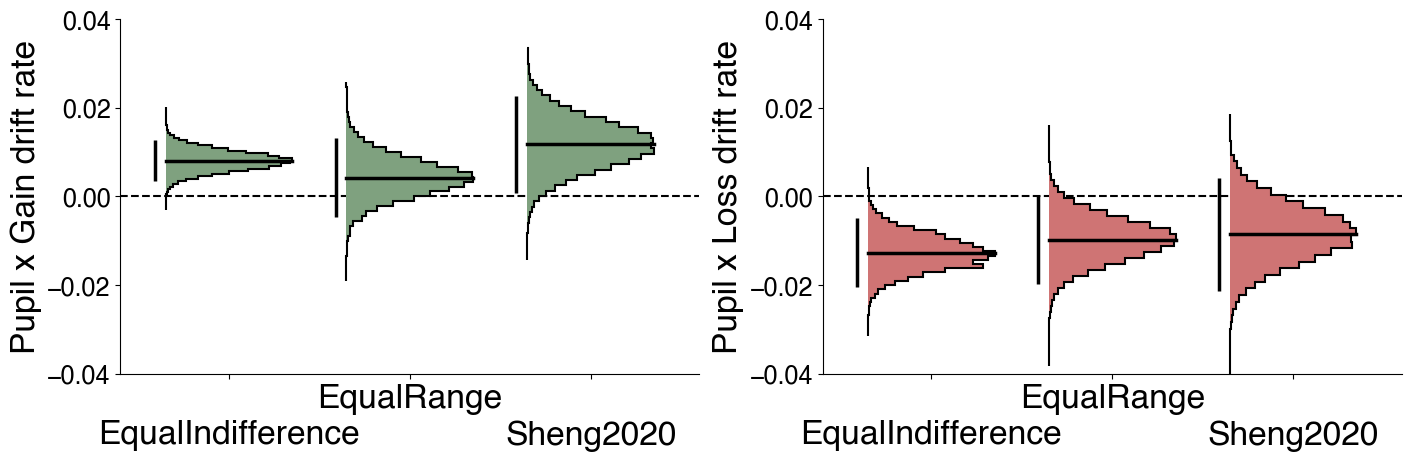

In [3]:
VALUATION_PUPIL_MODEL = "HDDM_Base_Pupil_valuation"
VALUATION_PUPIL_YLIM = (-0.04, 0.04)

# (param, y-label, color) -- one panel each
VALUATION_PUPIL_PANELS = [
    ("v_gain_centered:pupil", "Pupil x Gain drift rate", "#7FA17F"),
    ("v_loss_centered:pupil", "Pupil x Loss drift rate", "#CF7474"),
]

fig, axes = plt.subplots(nrows=1, ncols=len(VALUATION_PUPIL_PANELS), figsize=(14, 4.5),
                         layout="constrained")
for ax, (param, ylabel, color) in zip(axes, VALUATION_PUPIL_PANELS):
    plot_posterior_hists(ax, VALUATION_PUPIL_MODEL, param, color, ylabel, VALUATION_PUPIL_YLIM)

fig.savefig("saved/figureS10.svg", dpi=300, bbox_inches="tight")
plt.show()

### ln(BF) and table: Pupil x Gain and Pupil x Loss posteriors
ln Bayes Factor for each parameter being >0 vs. <0 (positive = evidence for >0), and the group-level posterior mean [95% posterior interval] per dataset, written to `results/ddm_valuation_pupil_posterior_tables.tex` in the format of `figure5_v2.ipynb`'s table.

In [5]:
TABLE_DATASET_NAMES = {
    "equalIndifference": "EqualIndifference",
    "equalRange": "EqualRange",
    "sheng2020": "Sheng2020",
}
PARAM_LABELS = {
    "v_gain_centered:pupil": "Pupil x Gain drift",
    "v_loss_centered:pupil": "Pupil x Loss drift",
}

rows = []
for param, _, _ in VALUATION_PUPIL_PANELS:
    for ds in DATASETS:
        samples, mean, lo, hi = summarize_posterior(VALUATION_PUPIL_MODEL, ds, param)
        rows.append({"parameter": PARAM_LABELS[param], "dataset": TABLE_DATASET_NAMES[ds],
                     "mean": mean, "ci_lower": lo, "ci_upper": hi, "ln_bf": ln_bf_sign(samples)})
posterior_summary = pd.DataFrame(rows)

print(posterior_summary.pivot(index="parameter", columns="dataset", values="ln_bf")
      [list(TABLE_DATASET_NAMES.values())].round(3).to_string())


def format_posterior_cell(row):
    """Mean [95% posterior interval]."""
    return f"{row['mean']:.3f} [{row['ci_lower']:.3f}, {row['ci_upper']:.3f}]"


def write_posterior_table(f, title, caption, summary):
    f.write(f"\\subsection*{{{title}}}\n\n")
    f.write("\\begin{table}[h!]\n")
    f.write("\\centering\n")
    f.write("\\begin{tabular}{l" + "c" * len(DATASETS) + "}\n")
    f.write("\\hline\n")
    header = ["Parameter"] + [TABLE_DATASET_NAMES[ds] for ds in DATASETS]
    f.write(" & ".join(header) + " \\\\\n")
    f.write("\\hline\n")
    for param, _, _ in VALUATION_PUPIL_PANELS:
        cells = [PARAM_LABELS[param]]
        for ds in DATASETS:
            row = summary[(summary["parameter"] == PARAM_LABELS[param])
                          & (summary["dataset"] == TABLE_DATASET_NAMES[ds])].iloc[0]
            cells.append(format_posterior_cell(row))
        f.write(" & ".join(cells) + " \\\\\n")
    f.write("\\hline\n")
    f.write("\\end{tabular}\n")
    f.write(f"\\caption{{{caption}}}\n")
    f.write("\\end{table}\n\n\n")
    f.write("\\newpage\n")


title = "Pupil x valuation DDM parameters"
caption = (
    "Group-level posterior mean [95\\% posterior interval] "
    "(2.5th--97.5th percentiles of the pooled samples) of the pupil modulation "
    "of the gain and loss drift weights."
)

output_path = results_pth / "ddm_valuation_pupil_posterior_tables.tex"
with open(output_path, "w") as f:
    write_posterior_table(f, title, caption, posterior_summary)

print()
print(output_path.read_text())

dataset             EqualIndifference  EqualRange  Sheng2020
parameter                                                   
Pupil x Gain drift              7.195       1.609      3.964
Pupil x Loss drift             -6.800      -3.629     -2.305

\subsection*{Pupil x valuation DDM parameters}

\begin{table}[h!]
\centering
\begin{tabular}{lccc}
\hline
Parameter & EqualIndifference & EqualRange & Sheng2020 \\
\hline
Pupil x Gain drift & 0.008 [0.003, 0.013] & 0.004 [-0.005, 0.013] & 0.012 [0.001, 0.023] \\
Pupil x Loss drift & -0.013 [-0.020, -0.005] & -0.010 [-0.020, 0.000] & -0.008 [-0.021, 0.004] \\
\hline
\end{tabular}
\caption{Group-level posterior mean [95\% posterior interval] (2.5th--97.5th percentiles of the pooled samples) of the pupil modulation of the gain and loss drift weights.}
\end{table}


\newpage

